Folie 22 Hausaufgabe

In [1]:
class Clock(object):

    def __init__(self, hours, minutes, seconds):
        """
        Die Parameter hours, minutes, seconds müssen Ganzzahlen 
        sein, und es muss gelten:
        0 <= h < 24
        0 <= m < 60
        0 <= s < 60
        """

        self.set_Clock(hours, minutes, seconds)

    def set_Clock(self, hours, minutes, seconds):

        if type(hours) == int and 0 <= hours and hours < 24:
            self._hours = hours
        else:
            raise TypeError("Stunden müssen Ganzzahlen zwischen 0 und 23 sein!")
        if type(minutes) == int and 0 <= minutes and minutes < 60:
            self.__minutes = minutes 
        else:
            raise TypeError("Minuten müssen Ganzzahlen zwischen 0 und 59 sein!")
        if type(seconds) == int and 0 <= seconds and seconds < 60:
            self.__seconds = seconds
        else:
            raise TypeError("Sekunden müssen Ganzzahlen zwischen 0 und 59 sein!")

    def __str__(self):

        return "{0:02d}:{1:02d}:{2:02d}".format(self._hours,
                                                self.__minutes,
                                                self.__seconds)

    def tick(self):

        if self.__seconds == 59:
            self.__seconds = 0
            if self.__minutes == 59:
                self.__minutes = 0
                if self._hours == 23:
                    self._hours = 0
                else:
                    self._hours += 1
            else:
                self.__minutes += 1
        else:
            self.__seconds += 1

In [2]:
class Calendar(object):

    months = (31,28,31,30,31,30,31,31,30,31,30,31)

    @staticmethod
    def leapyear(jahr):

        if jahr % 4 == 0:
            if jahr % 100 == 0:
                if jahr % 400 == 0:
                    schaltjahr = True
                else:
                    schaltjahr = False
            else:
                schaltjahr = True
        else:
            schaltjahr = False

        return schaltjahr


    def __init__(self, d, m, y):

        self.set_Calendar(d,m,y)


    def set_Calendar(self, d, m, y):

        if type(d) == int and type(m) == int and type(y) == int:
            self.__days = d
            self.__months = m
            self.__years = y
        else:
            raise TypeError("d, m, y müssen ganze Zahlen sein!")


    def __str__(self):


        return "{0:02d}.{1:02d}.{2:4d}".format(self.__days,
                                               self.__months,
                                               self.__years)


    def advance(self):

        max_days = Calendar.months[self.__months-1]
        if self.__months == 2 and Calendar.leapyear(self.__years):
            max_days += 1
        if self.__days == max_days:
            self.__days= 1
            if self.__months == 12:
                self.__months = 1
                self.__years += 1
            else:
                self.__months += 1
        else:
            self.__days += 1

In [11]:
#from clock import Clock
#from calendar import Calendar


class CalendarClock(Clock, Calendar):

    def __init__(self,day, month, year, hour, minute, second):
        Clock.__init__(self,hour, minute, second)
        Calendar.__init__(self,day, month, year)


    def tick(self):

        previous_hour = self._hours
        Clock.tick(self)
        if (self._hours < previous_hour): 
            self.advance()

    def __str__(self):

        return Calendar.__str__(self) + ", " + Clock.__str__(self)

cc = CalendarClock(31,12,2000,23,59,59)
cc.tick()
str(cc)

'01.01.2001, 00:00:00'

Folie 27

In [13]:
from math import sqrt
def execute (func, list):
    res = []
    for x in list:
        res.append(func(x))
    return res

results = execute(lambda x:x**2, range(10))
execute(lambda x:sqrt(x), results)


[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]

In [14]:
def plus_five(x):
    return x+5

results = execute(plus_five, range(10))
results

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

Folie 28

In [15]:
list(map(lambda x:x**2, range(10)))

[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]

In [16]:
for i in map(lambda x:x**2, range(10)):
    print(i)

0
1
4
9
16
25
36
49
64
81


In [17]:
print(list(map(lambda x,y: x*y, range(10), range(10))))

[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]


Folie 29 lambda, map

In [21]:
f_temp = range(100)
c_temp = list(map(lambda f: 5/9*(f-32),f_temp))

all(list(map(lambda f,c: round(9/5*c+32)==f,f_temp, c_temp)))

True

Folie 30

In [22]:
list(filter(lambda x: x%2==0, range(10)))

[0, 2, 4, 6, 8]

Folie 31

In [24]:
from functools import reduce

def faculty(x):
    return reduce(lambda x, y: x*y, range(1, x+1))
faculty(15)

1307674368000

Folie 32

In [1]:
import multiprocessing
from math import sin, sqrt
import time

try: cpus = multiprocessing.cpu_count() 
except NotImplementedError: cpus = 2
print(cpus)

pool = multiprocessing.Pool(processes=12) 
start = time.time()
pool.map(sin, range(12000))
end = time.time()
print (end-start)
pool.close()

12
0.23507189750671387


Folie 34 List comprehensions

In [26]:
l = [(x,y,z) for x in range(1,21) for y in range(1,21) for z in range(1,21) if x**2+y**2==z**2]
l

[(3, 4, 5),
 (4, 3, 5),
 (5, 12, 13),
 (6, 8, 10),
 (8, 6, 10),
 (8, 15, 17),
 (9, 12, 15),
 (12, 5, 13),
 (12, 9, 15),
 (12, 16, 20),
 (15, 8, 17),
 (16, 12, 20)]

Folie 35

In [27]:
from math import sqrt
n = 20
noPrimes = [j for i in range (2,int(sqrt(n))) for j in range(i*2,n,i)]
sorted(noPrimes)

[4, 6, 6, 8, 9, 10, 12, 12, 14, 15, 16, 18, 18]

In [28]:
from math import sqrt
n = 20
noPrimes = {j for i in range (2,int(sqrt(n))) for j in range(i*2,n,i)}
sorted(noPrimes)

[4, 6, 8, 9, 10, 12, 14, 15, 16, 18]

Folie 36 List comprehensions

In [31]:
def probability_of_two_dices(number):
    all = [(x,y) for x in range(1,7) for y in range (1,7)]
    selection = [(x,y) for (x,y) in all if x+y == number]
    return(len(selection)/len(all))

probability_of_two_dices(2)

0.027777777777777776

Folie 38

In [2]:
a = 0
l = [1,2,3,4,5]
iter_x = list.__iter__(l)
while (True):
    try:
        a += iter_x.__next__()
        print(a)
    except StopIteration:
        break

1
3
6
10
15


Folie 39

In [9]:
class Reverse:
   """Iterator for looping over a sequence backwards."""
   def __init__(self, data):
       self.data = data
       self.index = len(data)
   def __iter__(self):
       return self
   def __next__(self):
       if self.index == 0:
           raise StopIteration
       self.index = self.index - 1
       return self.data[self.index]
r = Reverse("Guten Tag")
list(r)

['g', 'a', 'T', ' ', 'n', 'e', 't', 'u', 'G']

In [10]:
class Reverse:
   """Iterator for looping over a sequence backwards."""
   def __init__(self, data):
       self.data = data
       self.index = len(data)
   def __iter__(self):
       return iter(self.data[::-1])
r = Reverse("Guten Tag")
list(r)

['g', 'a', 'T', ' ', 'n', 'e', 't', 'u', 'G']

Folie 40

In [12]:
def reverse(data):
    for index in range(len(data)-1, -1, -1):
        yield data[index]
list(reverse("Guten Tag"))

['g', 'a', 'T', ' ', 'n', 'e', 't', 'u', 'G']

Folie 41

In [13]:
def infinity_loop(list):
    while True:
        l = list.pop(0)
        yield l
        list.append(l)
a = 0
for i in infinity_loop(["Blaukraut","bleibt"]):
    a += 1
    print(i)
    if a == 10:
        break

Blaukraut
bleibt
Blaukraut
bleibt
Blaukraut
bleibt
Blaukraut
bleibt
Blaukraut
bleibt


In [15]:
import itertools
text = itertools.islice(infinity_loop(["Blaukraut","bleibt"]),0,11)
list(text)

['Blaukraut',
 'bleibt',
 'Blaukraut',
 'bleibt',
 'Blaukraut',
 'bleibt',
 'Blaukraut',
 'bleibt',
 'Blaukraut',
 'bleibt',
 'Blaukraut']

Folie 42 Generatoren und Iteratoren

In [18]:
from functools import reduce

def faculty(start=1):
    n = reduce(lambda x,y: x*y, range(1,start))
    #n = 1
    c = start
    while True:
        n *= c       
        yield n
        c+=1

for i,f in enumerate(faculty(4)):
    print(f)
    if i > 5:
        break

24
120
720
5040
40320
362880
3628800


Folie 43

In [19]:
def n_loop(list, n = None):
    i = 0
    while n == None or i < n:
        i += 1
        l = list.pop(0)
        msg = yield l
        print(f"msg:{msg}")
        n = msg if msg is not None and msg > 0 else n
        i = 0 if msg is not None and msg > 0 else i
        list.append(l)

loop = n_loop(["Blaukraut","bleibt"])
next(loop)
loop.send(8)
for i in loop:
    print(i)

msg:8
msg:None
Blaukraut
msg:None
bleibt
msg:None
Blaukraut
msg:None
bleibt
msg:None
Blaukraut
msg:None
bleibt
msg:None
Blaukraut
msg:None


Folie 44 Generatoren und Iteratoren

In [20]:
import random
def random_ones_and_zeros():
    p = 0.5
    while True:
        x = random.random()
        msg = yield 1 if x < p else 0
        if msg is not None and msg > 0:
            p = msg

r = random_ones_and_zeros()
next(r)
r.send(0.9)
for i in range(10):
    print(next(r))

1
1
1
1
1
1
1
1
1
0


Folie 45

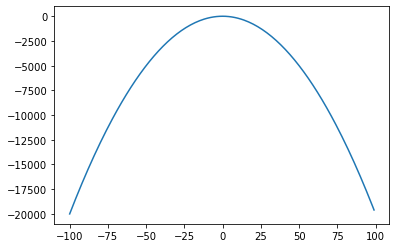

In [21]:
def polynomial_creator(a, b, c):
    def polonomial(x):
        return a * x**2 + b * x + c
    return polonomial

f = polynomial_creator(-2, 0, 0)
x =[]
y =[]
for i in range(-100,100):
    x.append(i)
    y.append(f(i))
    
import matplotlib.pyplot as plt
plt.plot(x,y)

Folie 46

In [22]:
def dekorateur(func):
    def wrapper(x):
        print("Methode " + func.__name__ + " wird mit " + str(x)+ " aufgerufen")
        print(func(x))
        print("Methode " + func.__name__ + " wurde aufgerufen")
    return wrapper

def f(x):
    return x**(1/2)
def g(name):
    return f"ich heiße {name}"
    
    
a = dekorateur(f)
g = dekorateur(g)
a(9)
g("hans")

from math import sin
sin_dek = dekorateur(sin)
sin_dek(90)

Methode f wird mit 9 aufgerufen
3.0
Methode f wurde aufgerufen
Methode g wird mit hans aufgerufen
ich heiße hans
Methode g wurde aufgerufen
Methode sin wird mit 90 aufgerufen
0.8939966636005579
Methode sin wurde aufgerufen


Folie 47

In [23]:
def dekorateur(func):
    def wrapper(x):
        print("Methode " + func.__name__ + " wird mit " + str(x)+ " aufgerufen")
        func(x)
        print("Methode " + func.__name__ + " wurde aufgerufen")
    return wrapper

@dekorateur
def f(x):
    print (x**2)

f(5)

Methode f wird mit 5 aufgerufen
25
Methode f wurde aufgerufen


Folie 49 Dekorateure

In [25]:
def only_natural_numbers(func):
    def helper(x):
        if type(x) == int and x >= 0:
            return func(x)
        else:
            raise Exception("Argument is not a natural Number!")
    return helper

@only_natural_numbers
def is_prime(n):
    return all(n%i for i in range(2,n))

is_prime(4)

False

Folie 50 Dekorateure

In [28]:
def call_counter(func):
    def helper(*args, **kwargs):
        helper.calls +=1
        return func(*args, **kwargs)
    helper.calls = 0
    return helper

@call_counter
def addition(a,b=5):
    return a+b

addition(3.5, b= 8)
addition.calls

1

Folie 51

In [33]:
def parameter_dek(choice):
    def check_parameters(func):
        def helper(*args):
            if choice in [int,float]:                
                for x in args:
                    if type(x) != choice:
                        raise Exception("{} is no {}".format(x, choice))
            else:
                raise Exception("Wrong Choice!")                
            return func(*args)
        return helper
    return check_parameters

def addition(a,b=0):
    return a+b
addition = parameter_dek(float)(addition)
addition(3.2,4.3)

@parameter_dek(float)
def addition(a,b=0):
    return a+b

addition(3.1, 0.5)

3.6

Folie 52

In [34]:
class Dekorateur:
    def __init__(self, f):
        self.f = f
    
    def __call__(self, *args, **kwargs):
        print("Funktion {} wird mit {} und {} aufgerufen".format(self.f.__name__, args, kwargs))
        self.f(*args, **kwargs)
        
@Dekorateur
def addition(a,b=0):
    return a+b

addition(3.5, b = 5)

Funktion addition wird mit (3.5,) und {'b': 5} aufgerufen


Folie 53 Memoization

In [36]:
class Memoize:
    def __init__(self, f):
        self.f = f
        self.memo = {}
    
    def __call__(self, *args, **kwargs):
        key = tuple(list(args)+list(kwargs.values()))
       
        if key not in self.memo:
            self.memo[key] = self.f(*args, **kwargs)
        else:
            print("calculation avoided from {} with arguments {}".format(self.f.__name__, key))
        return self.memo[key]
    
@Memoize
def addition(a, b=0):
    return a+b

addition(3, 5)
addition(3, b=5)
addition(3, 5)
addition(3, b=5)

addition(3)
addition(3)
addition(3, b=0)
addition(3,0)

calculation avoided from addition with arguments (3, 5)
calculation avoided from addition with arguments (3, 5)
calculation avoided from addition with arguments (3, 5)
calculation avoided from addition with arguments (3,)
calculation avoided from addition with arguments (3, 0)


3

Folie 54 Memoization (bessere Alternative)

In [2]:
import inspect

class Memoize:
    def __init__(self, f):
        self.f = f
        self.memo = {}
    
    def __call__(self, *args, **kwargs):
        kwargs_dict = kwargs
        params = inspect.signature(self.f).parameters.values()
        if len(params) > len(args):
            for param in inspect.signature(self.f).parameters.values():
                if param.default is not param.empty and param.name not in kwargs.keys():
                    kwargs_dict[param.name] = param.default                

        key = tuple((*args, *kwargs_dict.values()))
        if key not in self.memo:
            self.memo[key] = self.f(*args, **kwargs)
        else:
            print("calculation avoided from {} with arguments {}".format(self.f.__name__, key))
        return self.memo[key]
    
@Memoize
def addition(a, b=0):
    return a+b

addition(3, 5)
addition(3, b=5)
addition(3, 5)
addition(3, b=5)

addition(3)
addition(3)
addition(3, b=0)
addition(3,0)

calculation avoided from addition with arguments (3, 5)
calculation avoided from addition with arguments (3, 5)
calculation avoided from addition with arguments (3, 5)
calculation avoided from addition with arguments (3, 0)
calculation avoided from addition with arguments (3, 0)
calculation avoided from addition with arguments (3, 0)


3

Folie 57

In [3]:
"""Module mit mit Methoden zur Berechnung des Flächeninhaltes verschiedener geometrischer Formen"""
from math import pi

def square_fi(a):
    """Funktion zur Berechnung des Flächeninhaltes eines Quadrates der Seitenlänge a"""
    return rectangle_fi(a, a)

def rectangle_fi(a, b):
    """Funktion zur Berechnung des Flächeninhaltes eines Rechteckes der Seitenlänge a und b"""
    return a*b

if rectangle_fi(3,4) == 12 and square_fi(10) == 100:
    print("Alle Test erfolgreich!")
else:
    print("Mindestens ein Test ist fehlgeschlagen.")


Alle Test erfolgreich!


Folie 58

In [6]:
if __name__ == "__main__":
    if rectangle_fi(3,4) == 12 and square_fi(10) == 100:
        print("Alle Test erfolgreich!")
    else:
        print("Mindestens ein Test ist fehlgeschlagen.")


Alle Test erfolgreich!


In [10]:
import doctest
def rectangle_fi(a, b):
    """Funktion zur Berechnung des Flächeninhaltes eines Rechteckes der Seitenlänge a und b

    >>> rectangle_fi(4,5)
    20

    """
    return a*b+1
if __name__ == "__main__":
    doctest.testmod()

**********************************************************************
File "__main__", line 5, in __main__.rectangle_fi
Failed example:
    rectangle_fi(4,5)
Expected:
    20
Got:
    21
**********************************************************************
1 items had failures:
   1 of   1 in __main__.rectangle_fi
***Test Failed*** 1 failures.
